# 05 &nbsp;What does each choice cost, and which is worth it?

Notebooks 03 and 04 measured what each configuration gets right. This one puts a price on it, then answers the study's question: which choices improve answers per dollar? The answers were generated locally, so these runs paid no API fees. The dollar figures are what the same token counts would cost on a hosted model.

**Cost per 1,000 answers** = prompt and answer tokens counted by Ollama, times a hosted price for Gemma 4 E4B, plus the measured search and reranking time priced at a cloud hourly rate.

**The token price is a range, because no single price could be confirmed.** On November 20, 2026, the pricing pages of DeepInfra and Fireworks and OpenRouter's model list did not show Gemma 4 E4B. Third-party listings still do, and they disagree:

| Input / output, per million tokens | Listed for | Where |
|---|---|---|
| \$0.02 / \$0.10 (lowest, used below) | DeepInfra | [models.dev](https://models.dev/models/google/gemma-4-E4B-it/), [ComputePrices](https://computeprices.com/providers/deep-infra/models/gemma-4-e4b) (updated September 5, 2026) |
| \$0.15 / \$0.60 | GraphN | [models.dev](https://models.dev/models/google/gemma-4-E4B-it/) |
| \$0.20 / \$0.20 | Fireworks | [Price Per Token](https://pricepertoken.com/pricing-page/model/google-gemma-4-e4b-it) |
| \$0.30 / \$1.25 (highest, used below) | not named | [AI Flash Report](https://aiflashreport.com/models/gemma-4-e4b/) (verified July 20, 2026) |

Search and reranking are priced at \$0.145 an hour, the on-demand rate for a 4-vCPU AWS c7g.xlarge in us-east-1 ([DoiT](https://www.doit.com/compute/spot/us-east-1/c7g.xlarge)). The times were measured on an Apple M4, so this is an approximation.

In [1]:
import warnings

warnings.filterwarnings("ignore", message="urllib3 v2 only supports OpenSSL")  # old SSL on macOS system Python

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from ragdecisions import style
from ragdecisions.costs import chance_of_meeting_bar, cheapest_meeting_bar, cost_per_1000
from ragdecisions.data import DATASETS, RESULTS_DIR, load_questions
from ragdecisions.grid import config_name
from ragdecisions.stats import interval, resample_indices

style.use_style()
KEYS = ["chunk", "retriever", "rerank", "k"]

# Dollars per million tokens (input, output), as listed on November 20, 2026.
LISTINGS = {"$0.02 / $0.10": (0.02, 0.10), "$0.15 / $0.60": (0.15, 0.60),
            "$0.20 / $0.20": (0.20, 0.20), "$0.30 / $1.25": (0.30, 1.25)}
LOW, HIGH = "$0.02 / $0.10", "$0.30 / $1.25"
HOURLY = 0.145  # AWS c7g.xlarge on demand, us-east-1, 4 vCPUs

timing = pd.read_csv(RESULTS_DIR / "timing.csv")


def seconds(dataset, chunk, retriever, rerank):
    t = timing[(timing["dataset"] == dataset) & (timing["chunk"] == chunk)]
    search = t[(t["step"] == "search") & (t["retriever"] == retriever)]["seconds_per_query"].iloc[0]
    return search + (t[t["step"] == "rerank"]["seconds_per_query"].iloc[0] if rerank else 0)


def load(dataset):
    answers = pd.read_csv(RESULTS_DIR / f"answers_{dataset}.csv", keep_default_na=False, na_values=[""])
    grades = pd.read_csv(RESULTS_DIR / f"grades_{dataset}.csv", keep_default_na=False, na_values=[""])
    t = answers.merge(grades[["qid", "answer", "correct"]], on=["qid", "answer"])
    t["correct"] = t["correct"].astype(str).eq("True").astype(float)
    t["rerank"] = t["rerank"].astype(str).eq("True")
    t["answerable"] = t["qid"].map(load_questions(dataset).set_index("qid")["type"]) != "null"
    return t[t["k"] > 0]


tables, grids, configs = {}, {}, {}
for name in DATASETS:
    t = tables[name] = load(name)
    grids[name] = t[t["answerable"]].pivot_table(index="qid", columns=KEYS, values="correct")
    c = t.groupby(KEYS).agg(input_tokens=("prompt_tokens", "mean"), output_tokens=("answer_tokens", "mean"))
    c = c.loc[grids[name].columns].reset_index()
    c["seconds"] = [seconds(name, r.chunk, r.retriever, r.rerank) for r in c.itertuples()]
    c["accuracy"] = grids[name].mean().to_numpy() * 100
    for label, (p_in, p_out) in LISTINGS.items():
        c[label] = cost_per_1000(c["input_tokens"], c["output_tokens"], c["seconds"], p_in, p_out, HOURLY)
    c["name"] = [config_name(r.chunk, r.retriever, r.rerank, r.k) for r in c.itertuples()]
    configs[name] = c

overview = pd.DataFrame({DATASETS[name]: {
    "Prompt tokens, smallest to largest": f"{c['input_tokens'].min():,.0f} to {c['input_tokens'].max():,.0f}",
    "Answer tokens, average": f"{c['output_tokens'].mean():.1f}",
    "Dollars per 1,000 answers, lowest price": f"{c[LOW].min():.3f} to {c[LOW].max():.3f}",
    "Dollars per 1,000 answers, highest price": f"{c[HIGH].min():.3f} to {c[HIGH].max():.3f}",
    "Search and rerank, share of cost at low price": f"{(1000 * c['seconds'] * HOURLY / 3600 / c[LOW]).min():.0%} to {(1000 * c['seconds'] * HOURLY / 3600 / c[LOW]).max():.0%}",
    "Search and rerank, share of cost at high price": f"{(1000 * c['seconds'] * HOURLY / 3600 / c[HIGH]).min():.0%} to {(1000 * c['seconds'] * HOURLY / 3600 / c[HIGH]).max():.0%}",
} for name, c in configs.items()})
overview

,MultiHop-RAG,Natural Questions
"Prompt tokens, smallest to largest","641 to 5,446","499 to 5,842"
"Answer tokens, average",3.2,5.8
"Dollars per 1,000 answers, lowest price",0.014 to 0.183,0.012 to 0.190
"Dollars per 1,000 answers, highest price",0.198 to 1.712,0.163 to 1.818
"Search and rerank, share of cost at low price",0% to 68%,1% to 74%
"Search and rerank, share of cost at high price",0% to 12%,0% to 16%


The prompt is the bill. Answers average only 3.2 and 5.8 tokens, so output tokens barely count, and the largest prompts are 8.5 times the smallest on MultiHop-RAG and nearly 12 times on Natural Questions.

The token price changes what else matters. At the lowest price, search and reranking are up to 68% of the cost on MultiHop-RAG and 74% on Natural Questions. At the highest price they are at most 12% and 16%.

Building the index is a one-off cost and is not included. Embedding a corpus with bge-base at 128 tokens took about 3 minutes for MultiHop-RAG and 33 for Natural Questions on the M4, or about \$0.01 and \$0.08 at the same hourly rate.

## 1. Which choice buys the most accuracy per dollar?

Each choice averaged over every other setting in the answer grid. "Points per 10 cents" is the accuracy gained for each extra 10 cents per 1,000 answers.

In [2]:
CONTRASTS = [
    ("Add the reranker", "rerank", True, False),
    ("bge-base instead of keyword search", "retriever", "bge-base", "bm25"),
    ("512-token chunks instead of 128", "chunk", 512, 128),
    ("5 passages instead of 3", "k", 5, 3),
    ("10 passages instead of 3", "k", 10, 3),
]


def per_dime(points, dollars):
    if dollars <= 0:
        return "better and cheaper" if points > 0 else "worse and cheaper"
    return f"{points / dollars * 0.1:.1f}"


rows = []
for name, c in configs.items():
    for label, column, a, b in CONTRASTS:
        part = c[c["k"].isin([a, b])] if column == "k" else c
        mean = part.groupby(column)[["accuracy", LOW, HIGH]].mean()
        points = mean.loc[a, "accuracy"] - mean.loc[b, "accuracy"]
        d_low, d_high = mean.loc[a, LOW] - mean.loc[b, LOW], mean.loc[a, HIGH] - mean.loc[b, HIGH]
        rows.append({"dataset": DATASETS[name], "choice": label, "accuracy, points": f"{points:+.1f}",
                     "extra dollars per 1,000, low": f"{d_low:+.3f}", "extra dollars per 1,000, high": f"{d_high:+.3f}",
                     "points per 10 cents, low": per_dime(points, d_low), "points per 10 cents, high": per_dime(points, d_high)})
pd.DataFrame(rows).set_index(["dataset", "choice"])

accuracy, points  \
dataset           choice                                                
MultiHop-RAG      Add the reranker                               +8.6   
                  bge-base instead of keyword search             -2.5   
                  512-token chunks instead of 128               +10.3   
                  5 passages instead of 3                        +9.2   
                  10 passages instead of 3                      +19.9   
Natural Questions Add the reranker                               +6.1   
                  bge-base instead of keyword search             +7.9   
                  512-token chunks instead of 128               +12.2   
                  5 passages instead of 3                        +4.4   
                  10 passages instead of 3                       +7.5   

                                                     extra dollars per 1,000, low  \
dataset           choice                                                            
MultiHop-RAG      Add the reranker                                         +0.048   
                  bge-base instead of keyword search                       -0.002   
                  512-token chunks instead of 128                          +0.069   
                  5 passages instead of 3                                  +0.013   
                  10 passages instead of 3                                 +0.046   
Natural Questions Add the reranker                                         +0.047   
                  bge-base instead of keyword search                       -0.005   
                  512-token chunks instead of 128                          +0.074   
                  5 passages instead of 3                                  +0.014   
                  10 passages instead of 3                                 +0.049   

                                                     extra dollars per 1,000, high  \
dataset           choice                                                             
MultiHop-RAG      Add the reranker                                          +0.054   
                  bge-base instead of keyword search                        -0.018   
                  512-token chunks instead of 128                           +0.686   
                  5 passages instead of 3                                   +0.199   
                  10 passages instead of 3                                  +0.697   
Natural Questions Add the reranker                                          +0.049   
                  bge-base instead of keyword search                        +0.010   
                  512-token chunks instead of 128                           +0.791   
                  5 passages instead of 3                                   +0.211   
                  10 passages instead of 3                                  +0.738   

                                                     points per 10 cents, low  \
dataset           choice                                                        
MultiHop-RAG      Add the reranker                                       17.9   
                  bge-base instead of keyword search        worse and cheaper   
                  512-token chunks instead of 128                        15.0   
                  5 passages instead of 3                                69.5   
                  10 passages instead of 3                               42.9   
Natural Questions Add the reranker                                       13.1   
                  bge-base instead of keyword search       better and cheaper   
                  512-token chunks instead of 128                        16.6   
                  5 passages instead of 3                                31.1   
                  10 passages instead of 3                               15.2   

                                                     points per 10 cents, high  
dataset           choice                                            

**The best first upgrade depends on the token price.** The reranker adds about 5 cents per 1,000 answers whatever tokens cost, because its cost is machine time. More passages and longer chunks cost tokens, so their price moves with the token price.

- **At the lowest price, add passages before the reranker.** Going from three passages to five buys 69.5 points per \$0.10 on MultiHop-RAG and 31.1 on Natural Questions, well ahead of the reranker's 17.9 and 13.1.
- **At the highest price, add the reranker before more passages.** It buys 15.9 and 12.4 points per \$0.10, against 4.6 and 2.1 for five passages.
- **Longer chunks and ten passages are the costliest routes at high token prices:** 1.0 to 2.9 points per \$0.10. Longer chunks alone make a configuration about 3 to 3.6 times as expensive.
- **The retriever is close to free, so choose it for accuracy.** On Natural Questions bge-base adds 7.9 points for almost no change in cost. On MultiHop-RAG it is 2.5 points lower, and notebook 03 could not tell that from zero.

## 2. Where do returns stop?

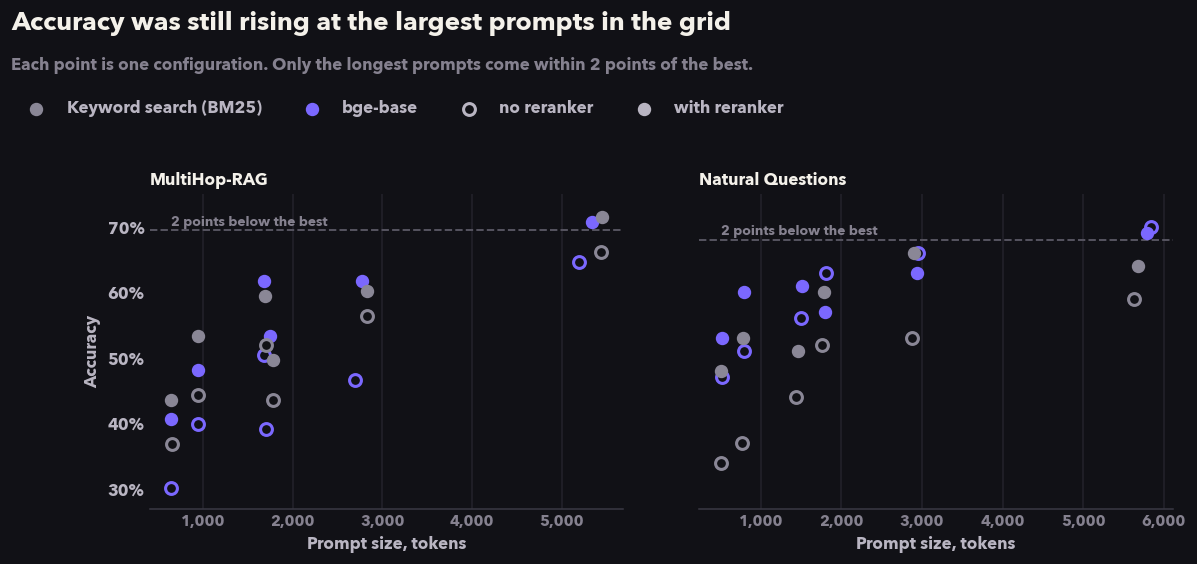

                                             MultiHop-RAG         Natural Questions
smallest prompt within 2 points              5,336 tokens              5,789 tokens
configuration                    bge-base 512 +rerank k10  bge-base 512 +rerank k10
accuracy                                            70.7%                     69.0%

MultiHop-RAG questions the articles cannot answer, answered anyway, by passages in the prompt: {3: 0.0, 5: 0.0, 10: 0.0}


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
plateau = {}
for ax, name in zip(axes, DATASETS):
    c = configs[name].sort_values("input_tokens")
    for (key, reranked), part in c.groupby(["retriever", "rerank"]):
        color = style.RETRIEVER_COLORS[key]
        kwargs = {"color": color} if reranked else {"facecolor": style.SURFACE, "edgecolor": color, "lw": 2}
        ax.scatter(part["input_tokens"], part["accuracy"], s=60, zorder=3, **kwargs)
    best = c["accuracy"].max()
    ax.axhline(best - 2, color=style.FLOOR_COLOR, lw=1.3, ls="--")
    ax.text(c["input_tokens"].min(), best - 1.7, "2 points below the best", color=style.MUTED, fontsize=9, va="bottom")
    plateau[DATASETS[name]] = c[c["accuracy"] >= best - 2].iloc[0]
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0f}%")
    ax.set_xlabel("Prompt size, tokens")
    ax.set_ylim(27, 75)
    ax.set_title(DATASETS[name], loc="left", color=style.INK, fontsize=11)
axes[0].set_ylabel("Accuracy")
for key in ["bm25", "bge-base"]:
    axes[0].scatter([], [], s=60, color=style.RETRIEVER_COLORS[key], label=style.RETRIEVER_LABELS[key])
axes[0].scatter([], [], s=60, facecolor=style.SURFACE, edgecolor=style.INK_2, lw=2, label="no reranker")
axes[0].scatter([], [], s=60, color=style.INK_2, label="with reranker")
fig.legend(loc="upper left", bbox_to_anchor=(0.015, 0.85), ncol=4)
style.headline(fig, "Accuracy was still rising at the largest prompts in the grid",
               "Each point is one configuration. Only the longest prompts come within 2 points of the best.")
fig.subplots_adjust(top=0.66, wspace=0.16)
style.save(fig, "accuracy_vs_prompt_size")
plt.show()

print(pd.DataFrame({k: {"smallest prompt within 2 points": f"{r['input_tokens']:,.0f} tokens", "configuration": r["name"],
                        "accuracy": f"{r['accuracy']:.1f}%"} for k, r in plateau.items()}).to_string())
mh = tables["multihop_rag"]
print("\nMultiHop-RAG questions the articles cannot answer, answered anyway, by passages in the prompt:",
      (1 - mh[~mh["answerable"]].groupby("k")["correct"].mean()).round(3).to_dict())

They did not stop inside this grid. The plan defined the plateau as the smallest prompt within 2 points of the best. On both datasets that is one of the largest prompts tested, about 5,300 tokens on MultiHop-RAG and 5,800 on Natural Questions. Longer prompts might still help; this study did not test them.

Longer prompts also did no harm on unanswerable questions: with 3, 5 or 10 passages, the model answered none of the MultiHop-RAG questions the articles cannot answer.

## 3. What is the cheapest configuration that meets a bar?

The plan's rule: the cheapest configuration with at least an 80% bootstrap chance of being within 1, 2 or 5 points of the best one. Each configuration is compared with the observed best on the same resampled questions.

In [4]:
BARS = [1, 2, 5]
draws, best_index = {}, {}
for name, grid in grids.items():
    draws[name] = grid.to_numpy()[resample_indices(len(grid))].mean(axis=1)
    best_index[name] = int(configs[name]["accuracy"].to_numpy().argmax())

rows = []
for name, c in configs.items():
    b = best_index[name]
    for bar in BARS:
        chance = chance_of_meeting_bar(draws[name], b, bar)
        picks = {label: cheapest_meeting_bar(draws[name], c[label], b, bar) for label in LISTINGS}
        pick = picks[LOW]
        rows.append({"dataset": DATASETS[name], "bar, points below best": bar,
                     "configurations passing": int((chance >= 0.8).sum()),
                     "cheapest that passes": c.loc[pick, "name"], "accuracy": f"{c.loc[pick, 'accuracy']:.1f}%",
                     "saving against the best, low": f"{1 - c.loc[pick, LOW] / c.loc[b, LOW]:.1%}",
                     "saving against the best, high": f"{1 - c.loc[pick, HIGH] / c.loc[b, HIGH]:.1%}",
                     "same pick at all four prices": len(set(picks.values())) == 1})
pd.DataFrame(rows).set_index(["dataset", "bar, points below best"])

configurations passing  \
dataset           bar, points below best                           
MultiHop-RAG      1                                            1   
                  2                                            1   
                  5                                            2   
Natural Questions 1                                            1   
                  2                                            1   
                  5                                            2   

                                              cheapest that passes accuracy  \
dataset           bar, points below best                                      
MultiHop-RAG      1                           bm25 512 +rerank k10    71.4%   
                  2                           bm25 512 +rerank k10    71.4%   
                  5                       bge-base 512 +rerank k10    70.7%   
Natural Questions 1                               bge-base 512 k10    70.0%   
                  2                               bge-base 512 k10    70.0%   
                  5                               bge-base 512 k10    70.0%   

                                         saving against the best, low  \
dataset           bar, points below best                                
MultiHop-RAG      1                                              0.0%   
                  2                                              0.0%   
                  5                                              1.1%   
Natural Questions 1                                              0.0%   
                  2                                              0.0%   
                  5                                              0.0%   

                                         saving against the best, high  \
dataset           bar, points below best                                 
MultiHop-RAG      1                                               0.0%   
                  2                                               0.0%   
                  5                                               1.9%   
Natural Questions 1                                               0.0%   
                  2                                               0.0%   
                  5                                               0.0%   

                                          same pick at all four prices  
dataset           bar, points below best                                
MultiHop-RAG      1                                               True  
                  2                                               True  
                  5                                               True  
Natural Questions 1                                               True  
                  2                                               True  
                  5                                               True

**With 133 and 100 questions, this rule could not approve a meaningfully cheaper configuration.** At the 1- and 2-point bars, only the best configuration passes on either dataset. At 5 points, MultiHop-RAG can swap keyword search for bge-base and save 1.1% to 1.9%; on Natural Questions the only other configuration that passes costs more. The picks are the same at all four listed prices.

That is a limit of the sample as much as a finding: being sure a cheaper configuration is within a few points takes more questions than this study has. The table below drops the 80% rule and shows the observed trade-off instead.

## 4. What does giving up some accuracy save?

In [5]:
rows = []
for name, c in configs.items():
    b = best_index[name]
    for label, price in [("low", LOW), ("high", HIGH)]:
        rows.append({"dataset": DATASETS[name], "token price": label, "accept": "the best", "configuration": c.loc[b, "name"],
                     "accuracy": f"{c.loc[b, 'accuracy']:.1f}%", "dollars per 1,000": f"{c.loc[b, price]:.3f}", "share of best's cost": "100%"})
        for give_up in [5, 10, 15]:
            within = c[c["accuracy"] >= c.loc[b, "accuracy"] - give_up - 1e-9]
            r = within.loc[within[price].idxmin()]
            rows.append({"dataset": DATASETS[name], "token price": label, "accept": f"up to {give_up} points less", "configuration": r["name"],
                         "accuracy": f"{r['accuracy']:.1f}%", "dollars per 1,000": f"{r[price]:.3f}", "share of best's cost": f"{r[price] / c.loc[b, price]:.0%}"})
pd.DataFrame(rows).set_index(["dataset", "token price", "accept"])

configuration  \
dataset           token price accept                                           
MultiHop-RAG      low         the best                  bm25 512 +rerank k10   
                              up to 5 points less   bge-base 512 +rerank k10   
                              up to 10 points less  bge-base 128 +rerank k10   
                              up to 15 points less  bge-base 128 +rerank k10   
                  high        the best                  bm25 512 +rerank k10   
                              up to 5 points less   bge-base 512 +rerank k10   
                              up to 10 points less  bge-base 128 +rerank k10   
                              up to 15 points less  bge-base 128 +rerank k10   
Natural Questions low         the best                      bge-base 512 k10   
                              up to 5 points less            bge-base 512 k5   
                              up to 10 points less           bge-base 512 k3   
                              up to 15 points less          bge-base 128 k10   
                  high        the best                      bge-base 512 k10   
                              up to 5 points less            bge-base 512 k5   
                              up to 10 points less   bge-base 128 +rerank k5   
                              up to 15 points less   bge-base 128 +rerank k5   

                                                   accuracy dollars per 1,000  \
dataset           token price accept                                            
MultiHop-RAG      low         the best                71.4%             0.183   
                              up to 5 points less     70.7%             0.182   
                              up to 10 points less    61.7%             0.057   
                              up to 15 points less    61.7%             0.057   
                  high        the best                71.4%             1.712   
                              up to 5 points less     70.7%             1.679   
                              up to 10 points less    61.7%             0.530   
                              up to 15 points less    61.7%             0.530   
Natural Questions low         the best                70.0%             0.118   
                              up to 5 points less     66.0%             0.060   
                              up to 10 points less    63.0%             0.037   
                              up to 15 points less    56.0%             0.031   
                  high        the best                70.0%             1.761   
                              up to 5 points less     66.0%             0.891   
                              up to 10 points less    60.0%             0.266   
                              up to 15 points less    60.0%             0.266   

                                                   share of best's cost  
dataset           token price accept                                     
MultiHop-RAG      low         the best                             100%  
                              up to 5 points less                   99%  
                              up to 10 points less                  31%  
                              up to 15 points less                  31%  
                  high        the best                             100%  
                              up to 5 points less                   98%  
                              up to 10 points less                  31%  
                              up to 15 points less                  31%  
Natural Questions low         the best                             100%  
                              up to 5 points less                   51%  
                              up to 10 points less                  32%  
                              up to 15 points less                  26%  
                  high        the best                             100%  
                              up to 5 points less    

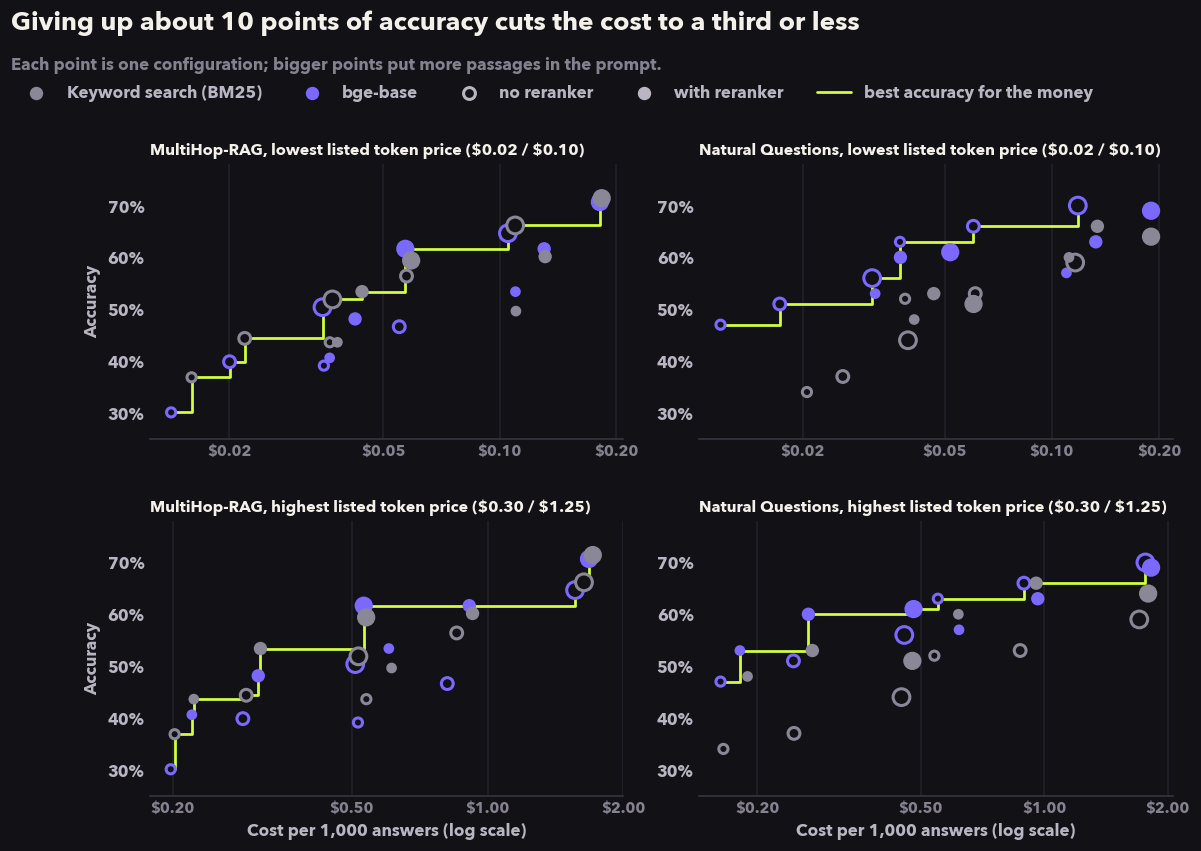

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.2))
for row, (label, price) in enumerate([("lowest listed token price", LOW), ("highest listed token price", HIGH)]):
    for col, name in enumerate(DATASETS):
        ax = axes[row, col]
        c = configs[name].sort_values(price)
        frontier = c[c["accuracy"] > c["accuracy"].cummax().shift(fill_value=-1)]
        ax.step(frontier[price], frontier["accuracy"], where="post", color=style.HIGHLIGHT, lw=1.8, zorder=2)
        for (key, reranked), part in c.groupby(["retriever", "rerank"]):
            color = style.RETRIEVER_COLORS[key]
            kwargs = {"color": color} if reranked else {"facecolor": style.SURFACE, "edgecolor": color, "lw": 2}
            ax.scatter(part[price], part["accuracy"], s=part["k"] * 12, zorder=3, **kwargs)
        ax.set_xscale("log")
        ax.set_xticks([0.02, 0.05, 0.10, 0.20] if price == LOW else [0.20, 0.50, 1.00, 2.00])
        ax.minorticks_off()
        ax.xaxis.set_major_formatter(lambda x, _: f"${x:.2f}")
        ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0f}%")
        ax.set_ylim(25, 78)
        ax.set_title(f"{DATASETS[name]}, {label} ({price})", loc="left", color=style.INK, fontsize=10.5)
        if row == 1:
            ax.set_xlabel("Cost per 1,000 answers (log scale)")
        if col == 0:
            ax.set_ylabel("Accuracy")
for key in ["bm25", "bge-base"]:
    axes[0, 0].scatter([], [], s=60, color=style.RETRIEVER_COLORS[key], label=style.RETRIEVER_LABELS[key])
axes[0, 0].scatter([], [], s=60, facecolor=style.SURFACE, edgecolor=style.INK_2, lw=2, label="no reranker")
axes[0, 0].scatter([], [], s=60, color=style.INK_2, label="with reranker")
axes[0, 0].plot([], [], color=style.HIGHLIGHT, lw=1.8, label="best accuracy for the money")
fig.legend(loc="upper left", bbox_to_anchor=(0.015, 0.915), ncol=5)
style.headline(fig, 'Giving up about 10 points of accuracy cuts the cost to a third or less', "Each point is one configuration; bigger points put more passages in the prompt.")
fig.subplots_adjust(top=0.81, hspace=0.3, wspace=0.16)
style.save(fig, "accuracy_vs_cost")
plt.show()

These are observed accuracies, not guarantees. Between any two single configurations, this sample can only detect differences of about 9 points on MultiHop-RAG and 11 on Natural Questions (notebook 01).

The trade-off is still large. Accepting up to 10 points less brings the cost to 31% of the best on MultiHop-RAG (61.7% accuracy), and to 32% or 15% on Natural Questions at the low and high token price (63.0% and 60.0%). On MultiHop-RAG, accepting up to 15 points saves nothing more.

## 5. Does the answer transfer between datasets?

In [7]:
a, b = grids["multihop_rag"], grids["natural_questions"][grids["multihop_rag"].columns]
observed = spearmanr(a.mean(), b.mean()).correlation
replicates = [spearmanr(a.to_numpy()[i].mean(axis=0), b.to_numpy()[j].mean(axis=0)).correlation
              for i, j in zip(resample_indices(len(a)), resample_indices(len(b), seed=1))]
low, high = interval(np.array(replicates))
print(f"Rank correlation of configuration accuracy between the two datasets: {observed:.2f} (interval {low:.2f} to {high:.2f})")
for name, c in configs.items():
    print(f"{DATASETS[name]}: best configuration is {c.loc[best_index[name], 'name']}, {c.loc[best_index[name], 'accuracy']:.1f}%")

Rank correlation of configuration accuracy between the two datasets: 0.61 (interval 0.34 to 0.75)
MultiHop-RAG: best configuration is bm25 512 +rerank k10, 71.4%
Natural Questions: best configuration is bge-base 512 k10, 70.0%


Only partly. The rank correlation of configuration accuracy between the two datasets is 0.61, with an interval from 0.34 to 0.75. Both datasets do best with 512-token chunks and ten passages, but they disagree on the rest: keyword search with the reranker on MultiHop-RAG (71.4%), bge-base without it on Natural Questions (70.0%).

## The decision

| If you want to | Do this | Why |
|---|---|---|
| **Get the highest accuracy** | Use 512-token chunks and 10 passages, and test the retriever and reranker on your own questions | Best on both datasets, and accuracy was still rising at the largest prompts |
| **Spend about a third as much** | Use smaller or fewer passages and accept about 10 points less | 31% of the best's cost on MultiHop-RAG, 15% to 32% on Natural Questions |
| **Upgrade on cheap tokens** | Add passages before a reranker | 31 to 70 points per \$0.10 for going from three to five |
| **Upgrade on expensive tokens** | Add a reranker before more passages | 12 to 16 points per \$0.10, because its cost does not grow with the token price |
| **Choose between configurations cheaply** | Rank them by retrieval score on your own data, then generate answers for the last few | Retrieval ranks configurations almost as accuracy does (0.96 and 0.95, notebook 04) but overstates how much a change is worth |
| **Reuse someone else's settings** | Do not, without testing | The best configuration differed between the two datasets |

## What this cannot tell

- **The dollar figures are estimates.** No provider's own page confirmed a price for this model on the day, so costs are shown across the listed range. Search and reranking times come from an Apple M4, and keyword search is slower here than in a real search engine (notebook 02).
- **The sample is small.** The cheapest-configuration rule could not approve a meaningful saving, and small differences between two configurations cannot be told apart.
- **One model, one prompt, two English datasets with short answers.** Long-form answers, other domains, larger models or tuned prompts may behave differently.
- **Hosted features are not priced.** Prompt caching, batch discounts and retries would all change the cost.